[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/07_regularization_feature_selection.ipynb)

# 07 · Regularization & Feature Selection: Ridge, Lasso and Elastic Net

**Part 1 — Classical supervised learning** · Notebook 7 of 27

Notebook 05 built ridge regression, which shrinks coefficients toward zero. Notebook 06 showed why that helps: shrinking trades a little bias for a lot less variance. This notebook asks the next question: **which features should be in the model at all?** We'll start with the brute-force answer (try every subset), see why it doesn't scale, and then build the elegant fix, the **Lasso**, from scratch. Its $\ell_1$ penalty sets coefficients **exactly** to zero, so it does feature selection automatically, by solving a convex problem. We'll finish by reconstructing an image from fewer measurements than it has pixels, which works only because of the Lasso.

**What you'll learn**

1. Why select features, and selection vs. extraction
2. Best-subset selection (and why $2^p$ is a problem) and forward stepwise selection
3. Ridge revisited: shrinks everything, selects nothing
4. **The Lasso**, and the 1-D calculation that explains everything: soft thresholding
5. The geometry: why corners give zeros
6. Solving the Lasso from scratch with **coordinate descent**
7. Lasso paths and choosing $\lambda$ by cross-validation
8. Recovering the true features: OLS vs. ridge vs. Lasso
9. **Elastic net**: when features come in correlated groups
10. **Compressed sensing**: recovering an image from too few measurements

*Course map: ISYE 4600 W5 (Feature Selection: subset selection, ridge, LASSO, elastic net, compressive sensing) and HW2 (medical imaging reconstruction with lasso vs. ridge); CX 4240 Lecture 6 (MAP with a Laplacian prior gives the Lasso).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from itertools import combinations
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso, ElasticNet, Ridge
import warnings; warnings.filterwarnings("ignore", category=UserWarning)
print("Ready ✓")

# Diabetes data from notebooks 05/06, standardized; y centered so the intercept drops out
D = load_diabetes(scaled=False)
feat = ["age", "sex", "bmi", "bp", "tc", "ldl", "hdl", "tch", "ltg", "glu"]
feat_long = dict(age="age", sex="sex", bmi="body-mass index", bp="blood pressure", tc="total cholesterol",
                 ldl="LDL", hdl="HDL", tch="chol./HDL", ltg="log triglycerides", glu="blood sugar")
Xd = (D.data - D.data.mean(0)) / D.data.std(0)
yd = D.target - D.target.mean()
m, p = Xd.shape

def kfold(m_, K, seed=0):
    return np.array_split(np.random.default_rng(seed).permutation(m_), K)

def cv_mse(fit_predict, X, y, K=10, seed=0):
    """fit_predict(Xtr, ytr, Xva) -> predictions on Xva. Returns mean and standard error of fold MSEs."""
    errs = []
    for va in kfold(len(y), K, seed):
        tr = np.setdiff1d(np.arange(len(y)), va)
        errs.append(np.mean((fit_predict(X[tr], y[tr], X[va]) - y[va]) ** 2))
    return np.mean(errs), np.std(errs, ddof=1) / np.sqrt(K)

ols = lambda Xtr, ytr, Xva: Xva @ np.linalg.lstsq(Xtr, ytr, rcond=None)[0] if Xtr.shape[1] else np.zeros(len(Xva))

Setup complete ✓


Ready ✓


---
## 1. Why select features?

ISYE 4600 (W5) motivates this with the apartment example: rent, location, living area, number of bedrooms, number of bathrooms... Several of these carry **redundant** information (bigger apartments have more bedrooms *and* more bathrooms). Including everything has costs:

- **Variance.** Every extra coefficient is one more number estimated from noisy data. Notebook 05 showed correlated features make coefficients wildly unstable.
- **Spurious correlations.** With many features, some will correlate with the target by pure chance. ISYE's example from text classification: a rare word like *arachnocentric* that happened to appear only in China-related training documents gets treated as a strong "China" signal. Notebook 06's leakage demo was the extreme version: 5,000 random features, some of which looked predictive.
- **Interpretability and cost.** A doctor can act on "these 3 measurements matter," not on 10,000 tiny weights. Fewer features also means fewer things to measure, store and compute.

Two kinds of dimensionality reduction:

| | **Feature selection** (this notebook) | **Feature extraction** (notebook 16, PCA) |
|---|---|---|
| Output | a *subset* of the original features | *new* features, combinations of the originals |
| Interpretable? | yes: "bmi and blood pressure" | less: "0.4·bmi + 0.3·bp − 0.2·hdl ..." |
| Uses the target $y$? | usually | PCA doesn't |

Feature selection has two ingredients (ISYE W5): an **evaluation metric** (what makes a subset "good"?) and a **search technique** (how do we find good subsets?).

---
## 2. Best-subset selection and forward stepwise selection

The most direct approach: for every possible subset of the $p$ features, fit least squares, and keep the best. With $p = 10$ diabetes features there are $2^{10} = 1024$ subsets, few enough to try them all.

What does "best" mean? **Not** training error: notebook 05 showed that adding a feature never increases training error, so "best by training error" always means "all features." We need an honest metric, like **cross-validated error** (notebook 06).

Fitted all 1024 subsets.


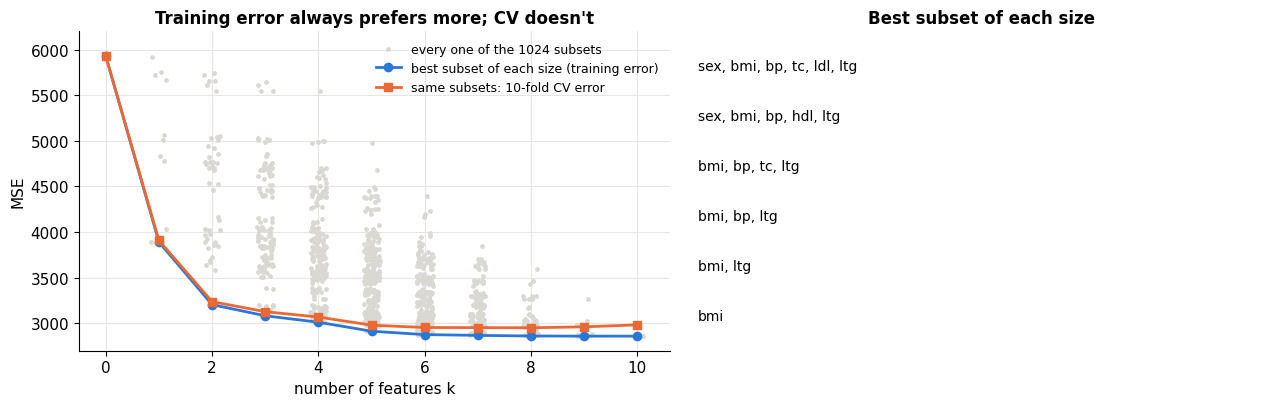

In [2]:
results = []
for k in range(0, p + 1):
    for S in combinations(range(p), k):
        S = list(S)
        th = np.linalg.lstsq(Xd[:, S], yd, rcond=None)[0] if S else np.zeros(0)
        train = np.mean((Xd[:, S] @ th - yd) ** 2) if S else np.mean(yd ** 2)
        results.append(dict(k=k, S=S, train=train))
res = pd.DataFrame(results)
print(f"Fitted all {len(res)} subsets.")

# Honest metric: 10-fold CV error, computed for the best-training subset of each size
best_per_k = res.loc[res.groupby("k").train.idxmin()].copy()
best_per_k["cv"] = [cv_mse(lambda a, b, c, S=S: ols(a[:, S], b, c[:, S]), Xd, yd)[0] for S in best_per_k.S]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(res))
ax1.scatter(res.k + jitter, res.train, s=6, color=C["light"], label="every one of the 1024 subsets")
ax1.plot(best_per_k.k, best_per_k.train, "-o", color=C["blue"], label="best subset of each size (training error)")
ax1.plot(best_per_k.k, best_per_k.cv, "-s", color=C["orange"], label="same subsets: 10-fold CV error")
ax1.set(xlabel="number of features k", ylabel="MSE", ylim=(2700, 6200), title="Training error always prefers more; CV doesn't")
ax1.legend(fontsize=9)
for _, row in best_per_k.iterrows():
    if 1 <= row.k <= 6:
        ax2.barh(f"k = {row.k}", 1, left=0, color="white")
        ax2.text(0.02, f"k = {row.k}", ", ".join(feat[j] for j in row.S), va="center", fontsize=10)
ax2.set(xlim=(0, 1), title="Best subset of each size"); ax2.axis("off")
fig.tight_layout(); plt.show()

Training error (blue) keeps falling all the way to $k = 10$, while CV error (orange) flattens out around $k = 4$–6: the last few features add noise, not signal. Look at the right panel too. Up to size 4 the best subsets are **nested** (bmi, then + ltg, then + bp, then + tc), but the best 5-set **drops** total cholesterol and adds sex and HDL instead. Features interact: tc is useful alongside LDL-like information, and a different combination covers the same ground better.

The catch is the cost. $2^p$ subsets is fine for $p = 10$, but $p = 40$ gives a trillion, and $p = 300$ gives more subsets than atoms in the universe. (Best subset is NP-hard in general.)

### Forward stepwise selection: a greedy shortcut

Start with no features. At each step, add the single feature that improves the fit the most. That's $p + (p-1) + \dots + 1 \approx p^2/2$ fits instead of $2^p$:

In [3]:
def forward_stepwise(X, y):
    chosen, remaining, path = [], list(range(X.shape[1])), []
    while remaining:
        scores = [np.mean((X[:, chosen + [j]] @ np.linalg.lstsq(X[:, chosen + [j]], y, rcond=None)[0] - y) ** 2) for j in remaining]
        j_best = remaining[int(np.argmin(scores))]
        chosen.append(j_best); remaining.remove(j_best)
        path.append((list(chosen), min(scores)))
    return path

fs = forward_stepwise(Xd, yd)
print(f"{'k':>2}  {'forward stepwise adds':<22} {'train MSE':>9} | best subset of size k (train MSE)")
for k, (S, tr) in enumerate(fs, 1):
    bs = best_per_k.set_index("k").loc[k]
    same = "✓ same" if set(S) == set(bs.S) else "✗ " + ",".join(feat[j] for j in bs.S) + f" ({bs.train:.0f})"
    print(f"{k:>2}  + {feat[S[-1]]:<20} {tr:9.0f} | {same}")

 k  forward stepwise adds  train MSE | best subset of size k (train MSE)
 1  + bmi                       3890 | ✓ same
 2  + ltg                       3205 | ✓ same
 3  + bp                        3083 | ✓ same
 4  + tc                        3012 | ✓ same
 5  + sex                       2966 | ✗ sex,bmi,bp,hdl,ltg (2914)
 6  + ldl                       2877 | ✓ same
 7  + tch                       2868 | ✓ same
 8  + glu                       2861 | ✓ same
 9  + hdl                       2860 | ✓ same
10  + age                       2860 | ✓ same


Greedy forward selection agrees with the exhaustive search at every size except 5: having committed to tc at step 4, it can't take it back, so it misses the better 5-set. That's the weakness of greedy search in general. There's also **backward elimination** (start with everything, drop the least useful) and hybrids. All of these share two problems: they're expensive when $p$ is large, and they're **unstable**, since a small change in the data can flip which feature gets added and send the whole path somewhere else.

What we'd like is a *continuous*, *convex* version of "use only a few features." That's the Lasso. First, let's see why ridge isn't it.

---
## 3. Ridge revisited: shrinks everything, selects nothing

ISYE 4600 (W5) runs a clean experiment: $m = 50$ examples, $p = 20$ features, but only some features truly matter. Let's build that and compare ridge's coefficients to the truth.

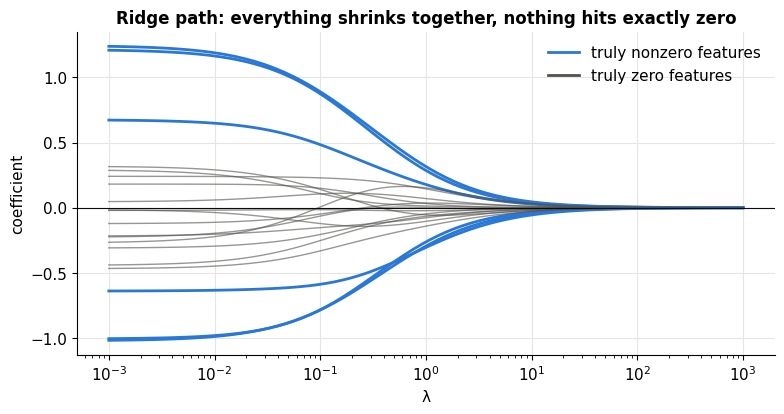

Number of exactly-zero ridge coefficients at λ = 1: 0


In [4]:
def make_sparse_problem(m=50, p=20, k_true=6, noise=1.0, rho=0.3, seed=0):
    """Gaussian features with pairwise correlation rho; only the first k_true have nonzero true coefficients."""
    r_ = np.random.default_rng(seed)
    cov = rho * np.ones((p, p)) + (1 - rho) * np.eye(p)
    X = r_.multivariate_normal(np.zeros(p), cov, size=m)
    beta = np.zeros(p); beta[:k_true] = r_.choice([-1, 1], k_true) * r_.uniform(0.6, 1.2, k_true)
    y = X @ beta + r_.normal(0, noise, m)
    return X, y, beta

Xs, ys, beta_true = make_sparse_problem()
Xs_c = (Xs - Xs.mean(0)) / Xs.std(0); ys_c = ys - ys.mean()

def ridge_fit(X, y, lam):
    """min (1/2m)||y − Xθ||² + (λ/2)||θ||²   (centered data, no intercept)."""
    return np.linalg.solve(X.T @ X / len(y) + lam * np.eye(X.shape[1]), X.T @ y / len(y))

lams_r = np.logspace(-3, 3, 80)
ridge_path = np.array([ridge_fit(Xs_c, ys_c, l) for l in lams_r])
fig, ax = plt.subplots(figsize=(9, 4.2))
for j in range(20):
    ax.plot(lams_r, ridge_path[:, j], color=C["blue"] if beta_true[j] != 0 else C["muted"],
            lw=2 if beta_true[j] != 0 else 1, alpha=1 if beta_true[j] != 0 else 0.6)
ax.plot([], [], color=C["blue"], lw=2, label="truly nonzero features"); ax.plot([], [], color=C["muted"], label="truly zero features")
ax.axhline(0, color=C["ink"], lw=0.8)
ax.set(xscale="log", xlabel="λ", ylabel="coefficient", title="Ridge path: everything shrinks together, nothing hits exactly zero"); ax.legend()
plt.show()
print("Number of exactly-zero ridge coefficients at λ = 1:", int(np.sum(ridge_fit(Xs_c, ys_c, 1.0) == 0)))

Ridge's intuition (ISYE W5): *use all features, but don't trust any single one too much.* The gray (truly useless) coefficients shrink, but so do the blue ones, and none of them ever reaches exactly zero. For prediction that's often fine; for **selection** it's useless.

---
## 4. The Lasso, and the 1-D calculation that explains everything

The **Lasso** (Least Absolute Shrinkage and Selection Operator; Tibshirani, 1996) swaps ridge's squared penalty for an absolute value:

$$\hat\theta_{\text{lasso}} = \arg\min_\theta\; \frac{1}{2m}\|y - X\theta\|_2^2 + \lambda\|\theta\|_1, \qquad \|\theta\|_1 = \sum_j |\theta_j|$$

(Constant factors like the $\frac12$ only rescale $\lambda$; we use scikit-learn's convention so we can check against it. ISYE writes $\frac1m\|\cdot\|^2 + \lambda\|\theta\|_1$, which is the same with $\lambda$ doubled.)

**Where it comes from.** Two views:

1. **Convex relaxation.** "Use at most $k$ features" means a constraint on $\|\theta\|_0$, the number of nonzeros. That's the combinatorial best-subset problem. The $\ell_1$ norm is the closest *convex* function to $\|\theta\|_0$, so replacing one with the other turns an NP-hard search into a convex problem.
2. **MAP with a Laplace prior** (CX 4240 Lecture 6). A Gaussian prior $p(\theta) \propto e^{-\lambda\|\theta\|_2^2}$ gave ridge. A **Laplace** prior $p(\theta) \propto e^{-\lambda\|\theta\|_1}$, which is sharply peaked at zero, gives the Lasso.

### The 1-D calculation (ISYE W5)

Everything about the Lasso is visible with a single parameter. Suppose one standardized feature, so the problem reduces to (up to constants) minimizing $\frac12(\theta - z)^2 + \text{penalty}$, where $z$ is the plain least-squares estimate.

- **Ridge:** $\frac12(\theta - z)^2 + \frac\lambda2\theta^2$. Derivative $\theta - z + \lambda\theta = 0$ gives $\hat\theta = \dfrac{z}{1 + \lambda}$. Proportional shrinkage. Zero only if $z = 0$.
- **Lasso:** $\frac12(\theta - z)^2 + \lambda|\theta|$. The absolute value has a kink at 0, so handle the cases:
  - if $\theta > 0$: $\theta - z + \lambda = 0 \Rightarrow \theta = z - \lambda$, valid when $z > \lambda$;
  - if $\theta < 0$: $\theta - z - \lambda = 0 \Rightarrow \theta = z + \lambda$, valid when $z < -\lambda$;
  - if $|z| \le \lambda$: neither case is valid, and the minimum sits right at the kink, $\theta = 0$.

$$\hat\theta_{\text{lasso}} = S_\lambda(z) = \text{sign}(z)\,\max(|z| - \lambda,\ 0) \qquad\text{(the soft-thresholding operator)}$$

There's a whole **interval** $[-\lambda, \lambda]$ of least-squares estimates that get mapped to exactly zero. Ridge has no such interval. For comparison, best-subset selection corresponds to **hard thresholding**: keep $z$ unchanged if it's big enough, else zero.

🎚️ **Compare the three operators**, and the penalized objectives behind them, as you change $\lambda$ and the least-squares estimate $z$:

In [5]:
soft = lambda z, lam: np.sign(z) * np.maximum(np.abs(z) - lam, 0)
zz = np.linspace(-3, 3, 400)

def plot_thresholds(lam=1.0, z0=0.7):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    ax1.plot(zz, zz, color=C["light"], lw=1.5, label="no penalty (θ̂ = z)")
    ax1.plot(zz, zz / (1 + lam), color=C["blue"], lw=2.5, label="ridge: z / (1 + λ)")
    ax1.plot(zz, soft(zz, lam), color=C["orange"], lw=2.5, label="lasso: soft threshold")
    ax1.plot(zz, np.where(np.abs(zz) > np.sqrt(2 * lam), zz, 0), color=C["green"], lw=1.8, ls="--", label="best subset: hard threshold")
    ax1.axvspan(-lam, lam, color=C["orange"], alpha=0.08)
    ax1.axvline(z0, color=C["ink"], lw=1, ls=":")
    ax1.set(xlabel="least-squares estimate z", ylabel="penalized estimate θ̂", title=f"λ = {lam:.2f}: lasso sends |z| ≤ λ to exactly 0", aspect="equal", xlim=(-3, 3), ylim=(-3, 3))
    ax1.legend(fontsize=9, loc="upper left")
    th = np.linspace(-2.5, 2.5, 500)
    obj_r = 0.5 * (th - z0) ** 2 + 0.5 * lam * th ** 2
    obj_l = 0.5 * (th - z0) ** 2 + lam * np.abs(th)
    ax2.plot(th, obj_r, color=C["blue"], lw=2, label="ridge objective"); ax2.plot(th, obj_l, color=C["orange"], lw=2, label="lasso objective")
    ax2.plot(z0 / (1 + lam), obj_r.min(), "o", color=C["blue"], ms=9); ax2.plot(soft(z0, lam), 0.5 * (soft(z0, lam) - z0) ** 2 + lam * abs(soft(z0, lam)), "o", color=C["orange"], ms=9)
    ax2.set(xlabel="θ", ylim=(0, 4), title=f"z = {z0:.2f}:  ridge θ̂ = {z0/(1+lam):.2f},  lasso θ̂ = {soft(z0, lam):.2f}"); ax2.legend(fontsize=9)
    fig.tight_layout(); plt.show()

interact(plot_thresholds, lam=FloatSlider(value=1.0, min=0.0, max=2.5, step=0.05, description="λ"),
         z0=FloatSlider(value=0.7, min=-3, max=3, step=0.05, description="z"));

Drag $z$ inside $[-\lambda, \lambda]$ and watch the right panel: the Lasso objective's minimum sits **on the kink at 0**. That kink is the whole story. A smooth penalty like $\theta^2$ has zero slope at the origin, so even a tiny pull from the data moves the optimum off zero. The absolute value has slope $\pm\lambda$ right at the origin, so the data's pull has to *exceed* $\lambda$ before the coefficient moves at all.

---
## 5. The geometry: why corners give zeros

The same story in 2-D, using the constrained form. Penalized and constrained versions are equivalent (notebook 03: $\lambda$ is a Lagrange multiplier), so think of it as

$$\min_\theta \|y - X\theta\|^2 \quad\text{subject to}\quad \|\theta\|_1 \le t \;\;\text{(lasso)} \quad\text{or}\quad \|\theta\|_2^2 \le t^2 \;\;\text{(ridge)}$$

The loss has elliptical contours centered at the least-squares solution. Grow the ellipse until it first touches the feasible region. The $\ell_2$ ball is round, so it's touched at a generic point. The $\ell_1$ ball is a diamond with corners **on the axes**, and an expanding ellipse very often hits a corner first, where one coordinate is exactly zero.

🎚️ **Move the least-squares solution around** and count how often the Lasso lands on a corner:

In [6]:
from scipy.optimize import minimize
def plot_geometry(cx=1.6, cy=0.6, corr=0.5):
    ctr = np.array([cx, cy]); Q = np.array([[1, corr], [corr, 1]])
    loss = lambda th: (th - ctr) @ Q @ (th - ctr)
    sols = {}
    for name, con in [("ridge", lambda t: 1 - t @ t), ("lasso", lambda t: 1 - np.abs(t).sum())]:
        sols[name] = minimize(loss, x0=[0.0, 0.0], constraints=[{"type": "ineq", "fun": con}], method="SLSQP").x
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    g = np.linspace(-2.5, 3, 300); G1, G2 = np.meshgrid(g, g)
    L = Q[0, 0] * (G1 - cx) ** 2 + 2 * Q[0, 1] * (G1 - cx) * (G2 - cy) + Q[1, 1] * (G2 - cy) ** 2
    tt = np.linspace(0, 2 * np.pi, 300)
    for ax, name, (bx, by) in [(axes[0], "ridge", (np.cos(tt), np.sin(tt))),
                               (axes[1], "lasso", (np.sign(np.cos(tt)) * np.cos(tt) ** 2, np.sign(np.sin(tt)) * np.sin(tt) ** 2))]:
        s = sols[name]
        ax.contour(G1, G2, L, levels=np.linspace(0.02, 12, 18), cmap="Blues_r", linewidths=1)
        ax.contour(G1, G2, L, levels=[loss(s)], colors=C["blue"], linewidths=2.5)
        ax.fill(bx, by, color=C["orange"], alpha=0.25); ax.plot(bx, by, color=C["orange"])
        ax.plot(cx, cy, "x", color=C["muted"], ms=12, mew=3)
        ax.plot(*s, "*", color=C["yellow"], ms=20, markeredgecolor=C["ink"])
        zero = "  ← one coefficient is exactly 0" if np.min(np.abs(s)) < 1e-4 else ""
        ax.set(xlim=(-2.5, 3), ylim=(-2.5, 3), aspect="equal", title=f"{name}: θ̂ = ({s[0]:.2f}, {s[1]:.2f}){zero}")
        ax.axhline(0, color=C["muted"], lw=0.6); ax.axvline(0, color=C["muted"], lw=0.6); ax.grid(False)
    fig.tight_layout(); plt.show()

interact(plot_geometry, cx=FloatSlider(value=1.6, min=-2.4, max=2.9, step=0.1, description="LS θ₁"),
         cy=FloatSlider(value=0.6, min=-2.4, max=2.9, step=0.1, description="LS θ₂"),
         corr=FloatSlider(value=0.5, min=-0.9, max=0.9, step=0.1, description="feature corr."));

In two dimensions the diamond has 4 corners and 4 edges, so the Lasso lands on a corner for a large fraction of positions. In high dimensions the $\ell_1$ ball is a **cross-polytope** that's almost all corners and low-dimensional edges, so sparse solutions become the norm rather than a coincidence.

---
## 6. Solving the Lasso from scratch: coordinate descent

The absolute value isn't differentiable at 0, so plain gradient descent doesn't apply directly. But the 1-D result from section 4 suggests a simple algorithm: **optimize one coordinate at a time**, holding the others fixed. Each 1-D subproblem is exactly the soft-threshold calculation.

For coordinate $j$, let $r^{(j)} = y - \sum_{k\ne j} X_k\theta_k$ be the **partial residual** (what's left to explain once every other feature has done its part). With standardized columns ($\frac1m\|X_j\|^2 = 1$), the best $\theta_j$ is

$$\theta_j \leftarrow S_\lambda\!\left(\tfrac{1}{m}X_j^\top r^{(j)}\right)$$

Cycle through $j = 1, \dots, p$ and repeat until nothing changes. This is how scikit-learn and glmnet solve the Lasso. It's convex, so coordinate descent converges to the global minimum.

In [7]:
def lasso_cd(X, y, lam, theta0=None, max_iter=1000, tol=1e-8, record=False):
    """min (1/2m)||y − Xθ||² + λ||θ||₁  by cyclic coordinate descent (columns of X standardized, y centered)."""
    m_, p_ = X.shape
    theta = np.zeros(p_) if theta0 is None else theta0.copy()
    col_sq = (X ** 2).sum(0) / m_                 # = 1 for standardized columns; kept general
    r = y - X @ theta                             # full residual, updated incrementally
    path = [theta.copy()]
    for it in range(max_iter):
        max_change = 0.0
        for j in range(p_):
            old = theta[j]
            rho = X[:, j] @ r / m_ + col_sq[j] * old   # = (1/m) X_jᵀ (partial residual without feature j)
            theta[j] = soft(rho, lam) / col_sq[j]
            if theta[j] != old:
                r -= X[:, j] * (theta[j] - old)
                max_change = max(max_change, abs(theta[j] - old))
            if record: path.append(theta.copy())
        if max_change < tol:
            break
    return (theta, np.array(path)) if record else theta

th_ours = lasso_cd(Xd, yd, lam=1.0)
th_sk = Lasso(alpha=1.0, fit_intercept=False, tol=1e-12, max_iter=100000).fit(Xd, yd).coef_
print("ours:   ", th_ours.round(3))
print("sklearn:", th_sk.round(3))
print("max difference:", np.abs(th_ours - th_sk).max().round(8))
print("features set to exactly zero:", [feat[j] for j in np.where(th_ours == 0)[0]])

ours:    [ -0.     -9.319  24.832  14.089  -4.839  -0.    -10.623   0.     24.421
   2.562]
sklearn: [ -0.     -9.319  24.832  14.089  -4.839  -0.    -10.623   0.     24.421
   2.562]
max difference: 1e-08
features set to exactly zero: ['age', 'ldl', 'tch']


Matches scikit-learn, and some coefficients are **exactly** zero: feature selection, for free.

Here's coordinate descent in 2-D, moving along one axis at a time on the Lasso objective's contours (notice the kinks in the contours along the axes, from $|\theta_1| + |\theta_2|$):

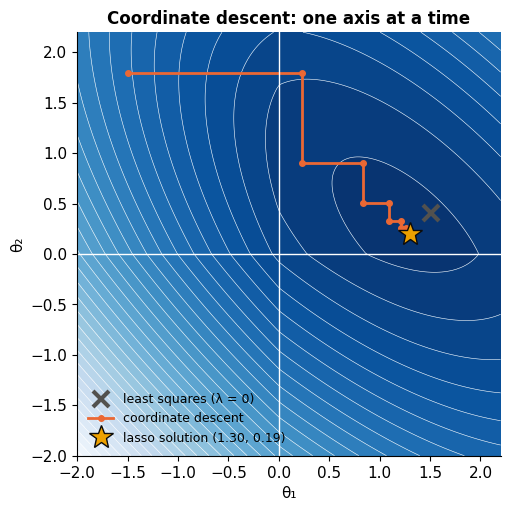

In [8]:
r_ = np.random.default_rng(2)
A2 = r_.normal(size=(60, 2)) @ np.array([[1, 0.7], [0, 0.7]]); A2 = (A2 - A2.mean(0)) / A2.std(0)
y2 = A2 @ np.array([1.5, 0.3]) + r_.normal(0, 0.8, 60); y2 -= y2.mean()
lam2 = 0.35
th_end, path2 = lasso_cd(A2, y2, lam2, theta0=np.array([-1.5, 1.8]), record=True)
obj = lambda t1, t2: np.mean((y2[:, None, None] - A2[:, 0, None, None] * t1 - A2[:, 1, None, None] * t2) ** 2, axis=0) / 2 + lam2 * (np.abs(t1) + np.abs(t2))
g = np.linspace(-2, 2.2, 160); T1, T2 = np.meshgrid(g, g); Z = obj(T1, T2)
th_ls = np.linalg.lstsq(A2, y2, rcond=None)[0]

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.contourf(T1, T2, Z, levels=30, cmap="Blues_r"); ax.contour(T1, T2, Z, levels=30, colors="white", linewidths=0.4)
ax.plot(*th_ls, "x", color=C["muted"], ms=12, mew=3, label="least squares (λ = 0)")
ax.plot(*path2[:24].T, "-o", color=C["orange"], ms=4, lw=2, label="coordinate descent")
ax.plot(*th_end, "*", color=C["yellow"], ms=18, markeredgecolor=C["ink"], label=f"lasso solution ({th_end[0]:.2f}, {th_end[1]:.2f})")
ax.axhline(0, color="white", lw=1); ax.axvline(0, color="white", lw=1)
ax.set(xlabel="θ₁", ylabel="θ₂", aspect="equal", title="Coordinate descent: one axis at a time"); ax.legend(fontsize=9, loc="lower left"); ax.grid(False)
plt.show()

Each step is a horizontal or vertical move to the 1-D minimum. Here the solution lands exactly on $\theta_2 = 0$: feature 2 is useful for least squares (the gray ×), but not useful *enough* to pay its $\lambda$ toll.

> 🤔 **Question: Is there a gradient-descent-style method for the Lasso?**
>
> Yes: **proximal gradient descent** (ISTA). Take an ordinary gradient step on the smooth squared-error part, then apply soft-thresholding to the result: $\theta \leftarrow S_{\eta\lambda}\big(\theta + \frac{\eta}{m}X^\top(y - X\theta)\big)$. It's two lines of code and handles any "smooth loss + $\ell_1$" problem, including $\ell_1$-regularized logistic regression and neural networks. Exercise 3 asks you to implement it.

---
## 7. Lasso paths and choosing λ by cross-validation

Sweep $\lambda$ from large to small. At very large $\lambda$ every coefficient is zero (the penalty dominates; in fact all coefficients are zero once $\lambda \ge \max_j |\frac1m X_j^\top y|$). As $\lambda$ shrinks, features **enter the model one at a time**. Using each solution as the starting point for the next ("warm starts") makes the whole path cheap.

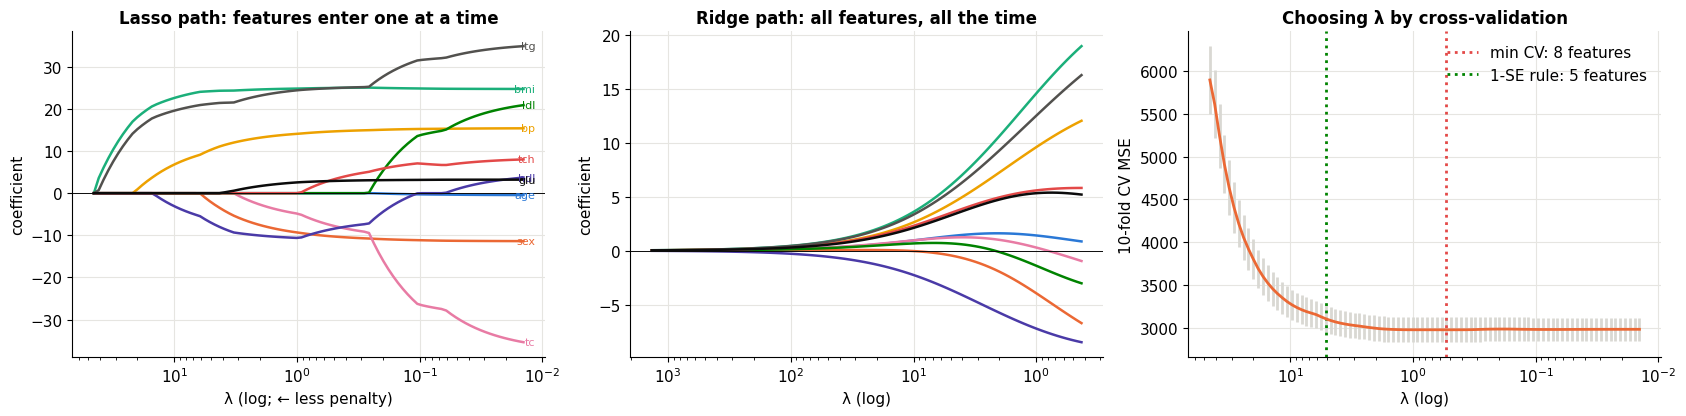

Order in which features enter: bmi → ltg → bp → hdl → sex → glu → tc → tch → ldl → age
1-SE model keeps: ['sex', 'body-mass index', 'blood pressure', 'HDL', 'log triglycerides']


In [9]:
lam_max = np.max(np.abs(Xd.T @ yd)) / m
lams = lam_max * np.logspace(0, -3.5, 90)
lasso_path, th = [], np.zeros(p)
for l in lams:
    th = lasso_cd(Xd, yd, l, theta0=th)          # warm start from the previous λ
    lasso_path.append(th.copy())
lasso_path = np.array(lasso_path)
ridge_path_d = np.array([ridge_fit(Xd, yd, l) for l in lams * 30])

# 10-fold CV over the same λ grid (fit inside each fold)
cv = np.array([cv_mse(lambda a, b, c, l=l: c @ lasso_cd(a, b, l), Xd, yd) for l in lams])
i_min = int(np.argmin(cv[:, 0])); i_1se = int(np.min(np.where(cv[:, 0] <= cv[i_min, 0] + cv[i_min, 1])[0]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
colors = [C[c] for c in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red", "muted", "ink"]]
for j in range(p):
    axes[0].plot(lams, lasso_path[:, j], color=colors[j], lw=1.8)
    axes[0].text(lams[-1] * 0.8, lasso_path[-1, j], feat[j], fontsize=8, va="center", ha="right", color=colors[j])
    axes[1].plot(lams * 30, ridge_path_d[:, j], color=colors[j], lw=1.8)
for ax in axes[:2]:
    ax.axhline(0, color=C["ink"], lw=0.7); ax.set(xscale="log", ylabel="coefficient")
axes[0].set(xlabel="λ (log; ← less penalty)", title="Lasso path: features enter one at a time"); axes[0].invert_xaxis()
axes[1].set(xlabel="λ (log)", title="Ridge path: all features, all the time"); axes[1].invert_xaxis()
axes[2].errorbar(lams, cv[:, 0], yerr=cv[:, 1], fmt="-", color=C["orange"], ecolor=C["light"])
axes[2].axvline(lams[i_min], color=C["red"], ls=":", label=f"min CV: {np.sum(lasso_path[i_min] != 0)} features")
axes[2].axvline(lams[i_1se], color=C["green"], ls=":", label=f"1-SE rule: {np.sum(lasso_path[i_1se] != 0)} features")
axes[2].set(xscale="log", xlabel="λ (log)", ylabel="10-fold CV MSE", title="Choosing λ by cross-validation"); axes[2].invert_xaxis(); axes[2].legend()
fig.tight_layout(); plt.show()
print("Order in which features enter:", " → ".join(feat[j] for j in np.argsort([np.argmax(lasso_path[:, j] != 0) if np.any(lasso_path[:, j] != 0) else 999 for j in range(p)])))
print("1-SE model keeps:", [feat_long[feat[j]] for j in np.where(lasso_path[i_1se] != 0)[0]])

The Lasso path reads like a ranking: bmi enters first, then ltg (log triglycerides), then blood pressure, and so on. The one-standard-error rule picks a much smaller model than the CV minimum with nearly the same predictive accuracy, which is the kind of model you'd actually report. This is ISYE 4600 W6's diabetes demo ("cross-validation to select $\lambda$ ... controls model sparsity and prediction performance").

> 🤔 **Question: The Lasso shrinks the coefficients it keeps, too. Isn't that biased?**
>
> Yes. The soft threshold subtracts $\lambda$ from every surviving coefficient, so big, important effects come out systematically too small. A common fix is the **relaxed Lasso**: use the Lasso only to choose *which* features to keep, then refit plain least squares on just those features. Penalties designed to avoid the bias (SCAD, MCP) also exist, at the cost of convexity.

---
## 8. Recovering the true features: OLS vs. ridge vs. Lasso

Back to the synthetic problem from section 3, where we know the truth: 20 features, only the first 6 matter. Fit all three methods (with $\lambda$ chosen by CV for ridge and Lasso) and compare to the true coefficients.

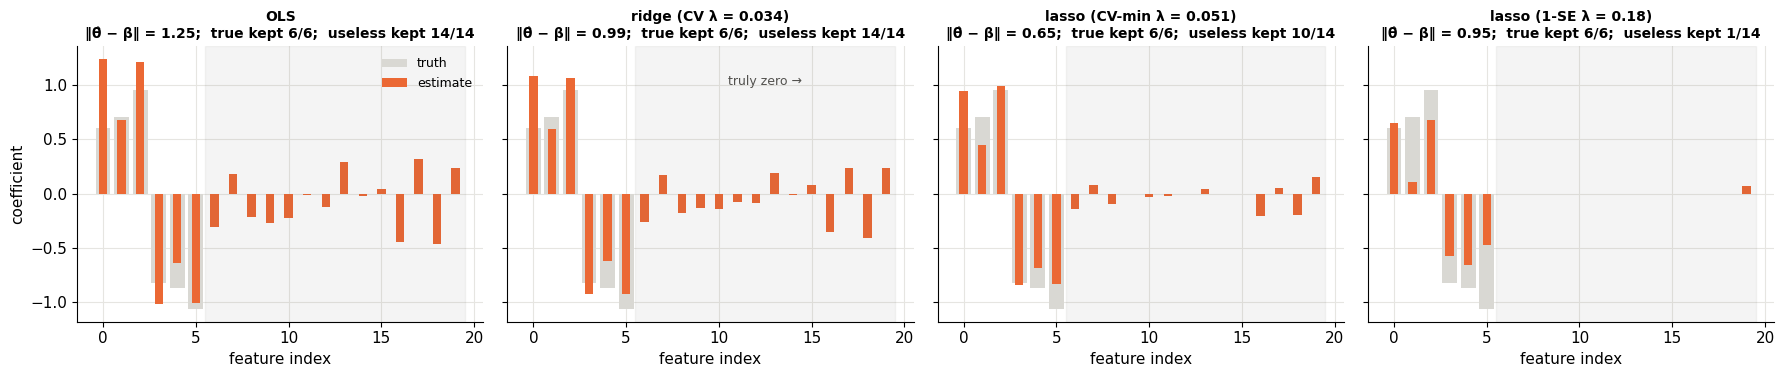

In [10]:
lam_grid = np.logspace(-3, 0.5, 40)
cv_lasso = np.array([cv_mse(lambda a, b, c, l=l: c @ lasso_cd(a, b, l), Xs_c, ys_c) for l in lam_grid])
cv_ridge = [cv_mse(lambda a, b, c, l=l: c @ ridge_fit(a, b, l), Xs_c, ys_c)[0] for l in lam_grid]
i_l = int(np.argmin(cv_lasso[:, 0]))
i_l1se = int(np.max(np.where(cv_lasso[:, 0] <= cv_lasso[i_l, 0] + cv_lasso[i_l, 1])[0]))   # largest λ within 1 SE
lam_r = lam_grid[int(np.argmin(cv_ridge))]
fits = {"OLS": np.linalg.lstsq(Xs_c, ys_c, rcond=None)[0],
        f"ridge (CV λ = {lam_r:.2g})": ridge_fit(Xs_c, ys_c, lam_r),
        f"lasso (CV-min λ = {lam_grid[i_l]:.2g})": lasso_cd(Xs_c, ys_c, lam_grid[i_l]),
        f"lasso (1-SE λ = {lam_grid[i_l1se]:.2g})": lasso_cd(Xs_c, ys_c, lam_grid[i_l1se])}
beta_std = beta_true * Xs.std(0)                     # truth on the standardized scale

fig, axes = plt.subplots(1, 4, figsize=(18, 3.9), sharey=True)
idx = np.arange(20)
for ax, (name, th) in zip(axes, fits.items()):
    ax.bar(idx, beta_std, color=C["light"], width=0.8, label="truth")
    ax.bar(idx, th, color=C["orange"], width=0.45, label="estimate")
    ax.axvspan(5.5, 19.5, color=C["muted"], alpha=0.06)
    nz = np.sum(np.abs(th[6:]) > 1e-10); kept = np.sum(np.abs(th[:6]) > 1e-10)
    ax.set(title=f"{name}\n‖θ̂ − β‖ = {np.linalg.norm(th - beta_std):.2f};  true kept {kept}/6;  useless kept {nz}/14", xlabel="feature index")
    ax.title.set_fontsize(10)
axes[0].set_ylabel("coefficient"); axes[0].legend(fontsize=9)
axes[1].text(12.5, 1.0, "truly zero →", fontsize=9, color=C["muted"], ha="center")
fig.tight_layout(); plt.show()

OLS gives every useless feature a nonzero coefficient, some of them sizable. Ridge shrinks them but keeps all 14. The two Lasso fits show a real tension:

- **CV-minimum λ:** the most accurate coefficients of all four (smallest $\|\hat\theta - \beta\|$), but it still keeps 10 useless features, with tiny coefficients. CV optimizes *prediction*, and a few tiny spurious coefficients barely hurt prediction, so CV tends to over-select.
- **One-standard-error λ:** keeps all 6 true features and only 1 useless one. That's the **selection** you'd want to report. The price is more shrinkage of the coefficients it keeps (larger error, the soft-threshold bias from section 4).

So the Lasso is good at both jobs, but "best for prediction" and "best for selection" call for different $\lambda$'s. Fitting plain least squares on the 1-SE Lasso's chosen features (the relaxed Lasso, exercise 4) gets the best of both.

> 🤔 **Question: Will the Lasso always find exactly the right features?**
>
> Not always. Theory says it recovers the true set with high probability when the true coefficients are large enough relative to the noise and the useless features aren't too correlated with the useful ones (the "irrepresentable condition"). With strongly correlated features it tends to pick one of a group more or less at random, which is section 9's topic. A practical check is **stability selection**: run the Lasso on many random half-samples of the data and keep only the features selected most of the time.

---
## 9. Elastic net: when features come in correlated groups

The Lasso has a weakness with **correlated** features: if three features carry nearly the same information, it tends to pick one and zero out the others, and *which* one can flip with tiny changes in the data (ISYE W5: "picks one arbitrarily"). Ridge has the opposite behavior: it splits the weight evenly across the group (notebook 05, section 10).

The **elastic net** (Zou & Hastie, 2005) uses both penalties:

$$\min_\theta\; \frac{1}{2m}\|y - X\theta\|^2 + \lambda\Big(\alpha\|\theta\|_1 + \frac{1-\alpha}{2}\|\theta\|_2^2\Big), \qquad \alpha \in [0, 1]$$

$\alpha = 1$ is the Lasso, $\alpha = 0$ is ridge. In between, it **selects** (the $\ell_1$ part still has corners) but tends to keep or drop correlated features **together** (the $\ell_2$ part rounds the corners slightly and favors sharing weight).

In [11]:
def correlated_groups(seed):
    r_ = np.random.default_rng(seed)
    z = r_.normal(size=(100, 1))
    group = z + 0.15 * r_.normal(size=(100, 3))           # 3 near-copies of one signal
    noise_feats = r_.normal(size=(100, 5))                 # 5 useless features
    X = np.hstack([group, noise_feats]); X = (X - X.mean(0)) / X.std(0)
    y = 2.0 * z[:, 0] + r_.normal(0, 1, 100); y -= y.mean()
    return X, y

print(f"{'sample':>6} | {'lasso: g1, g2, g3':^22} | {'elastic net: g1, g2, g3':^30} | noise feats kept (lasso / EN)")
for s in range(6):
    Xg, yg = correlated_groups(s)
    la = Lasso(alpha=0.3, fit_intercept=False).fit(Xg, yg).coef_
    en = ElasticNet(alpha=0.6, l1_ratio=0.5, fit_intercept=False).fit(Xg, yg).coef_
    fmt = lambda v: "  ".join(f"{x:5.2f}" for x in v)
    print(f"{s:>6} | {fmt(la[:3]):^22} | {fmt(en[:3]):^30} | {np.sum(la[3:] != 0)} / {np.sum(en[3:] != 0)}")

tot = np.zeros(4, int)
for s in range(30):
    Xg, yg = correlated_groups(s)
    la = Lasso(alpha=0.3, fit_intercept=False).fit(Xg, yg).coef_
    en = ElasticNet(alpha=0.6, l1_ratio=0.5, fit_intercept=False).fit(Xg, yg).coef_
    tot += [np.sum(la[:3] == 0), np.sum(la[3:] != 0), np.sum(en[:3] == 0), np.sum(en[3:] != 0)]
print(f"\nOver 30 samples: lasso dropped {tot[0]} of 90 group members and kept {tot[1]} of 150 noise features;")
print(f"                 elastic net dropped {tot[2]} of 90 group members and kept {tot[3]} of 150 noise features.")

sample |   lasso: g1, g2, g3    |    elastic net: g1, g2, g3     | noise feats kept (lasso / EN)
     0 |   0.00   1.54   0.10   |       0.47   0.56   0.46       | 0 / 0
     1 |   1.25   0.03   0.07   |       0.47   0.37   0.38       | 0 / 0
     2 |   1.03   0.34   0.24   |       0.53   0.47   0.47       | 0 / 0
     3 |   0.74   1.07   0.03   |       0.56   0.58   0.53       | 1 / 1
     4 |   0.36   0.55   1.04   |       0.57   0.58   0.62       | 0 / 0
     5 |   0.21   0.93   0.31   |       0.42   0.47   0.43       | 0 / 0

Over 30 samples: lasso dropped 17 of 90 group members and kept 2 of 150 noise features;
                 elastic net dropped 0 of 90 group members and kept 2 of 150 noise features.


Across samples, the Lasso's weight lurches between the three copies: often one gets most of it and another is zeroed out entirely, and which one changes from sample to sample. The elastic net spreads the weight evenly across all three every time, while keeping the 5 noise features at exactly zero just as reliably as the Lasso. Here are the unit balls behind the two behaviors:

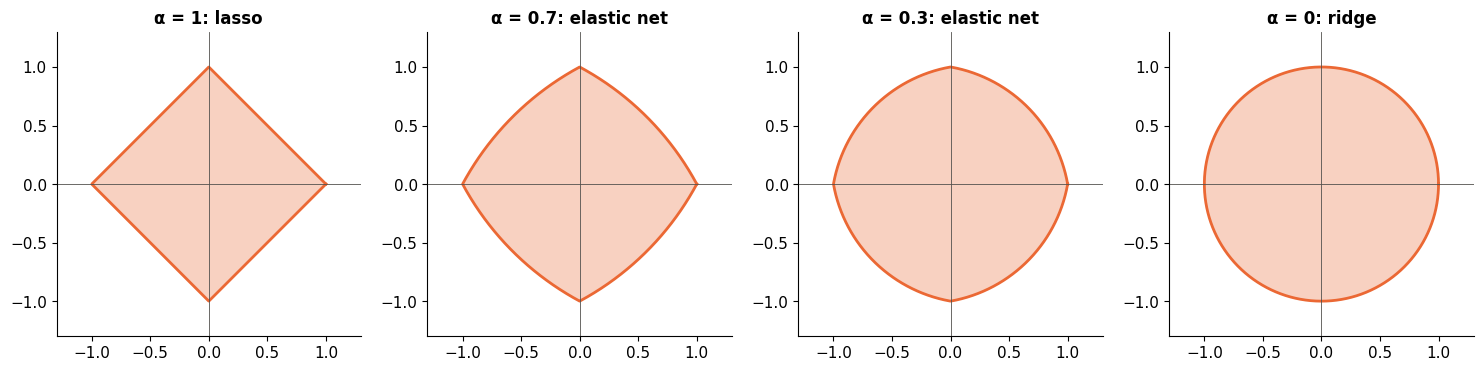

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
tt = np.linspace(0, 2 * np.pi, 2000); u = np.column_stack([np.cos(tt), np.sin(tt)])
for ax, a in zip(axes, [1.0, 0.7, 0.3, 0.0]):
    pen = lambda v: a * np.abs(v).sum(1) + (1 - a) / 2 * (v ** 2).sum(1) * 2    # scaled so the ball passes through (±1, 0)
    rad = np.array([1 / pen(np.array([d]))[0] if a > 0 else 1.0 for d in u])
    if a < 1 and a > 0:                                                        # solve pen(r·d) = 1 for r (quadratic)
        A_ = (1 - a) * (u ** 2).sum(1); B_ = a * np.abs(u).sum(1)
        rad = (-B_ + np.sqrt(B_ ** 2 + 4 * A_)) / (2 * A_)
    ax.fill(rad * u[:, 0], rad * u[:, 1], color=C["orange"], alpha=0.3); ax.plot(rad * u[:, 0], rad * u[:, 1], color=C["orange"], lw=2)
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal",
           title={1.0: "α = 1: lasso", 0.0: "α = 0: ridge"}.get(a, f"α = {a}: elastic net")); ax.grid(False)
    ax.axhline(0, color=C["muted"], lw=0.6); ax.axvline(0, color=C["muted"], lw=0.6)
fig.tight_layout(); plt.show()

The elastic net ball keeps sharp corners on the axes (so it still produces exact zeros) but its edges bulge outward (so, like ridge, it prefers to share weight among correlated features). In practice it's often the default choice when you expect groups of related features, like genes in the same pathway or pixels in the same region. It has two knobs, $\lambda$ and $\alpha$, both usually chosen by CV.

| Method | Assumes | Penalty | Selects? | With correlated features | Strength | Weakness |
|---|---|---|---|---|---|---|
| OLS | every feature matters | none | no | unstable | simple, unbiased | high variance |
| Ridge | many small effects | $\ell_2$ | no | shares weight | stable, good predictions | not interpretable |
| Lasso | a few important features | $\ell_1$ | yes | picks one arbitrarily | sparse, interpretable | unstable under correlation |
| Elastic net | sparse but grouped | $\ell_1 + \ell_2$ | yes | keeps groups together | stable *and* sparse | two hyperparameters |

*(Adapted from ISYE 4600 W5.)*

---
## 10. Compressed sensing: recovering an image from too few measurements

ISYE 4600's HW2 poses an MRI-inspired problem. An image has $p$ pixels, but instead of measuring each pixel directly, the scanner records $n$ **linear measurements**, each a random weighted sum of all pixels:

$$y = Ax + \epsilon, \qquad A \in \mathbb{R}^{n\times p}, \quad n < p$$

Fewer equations than unknowns means infinitely many images are consistent with the measurements. Plain least squares is hopeless. But if the image is **sparse** (mostly zeros), the Lasso can pick out the sparse one, treating each pixel as a "feature" to select. This idea, **compressed sensing** (Candès, Romberg & Tao; Donoho, 2006), is used in real MRI machines to cut scan times.

Our image: a 32×32 picture ($p = 1024$ pixels), of which only a small fraction are "on."

1024 pixels, only 166 of them on (16%); the other 84% are zero


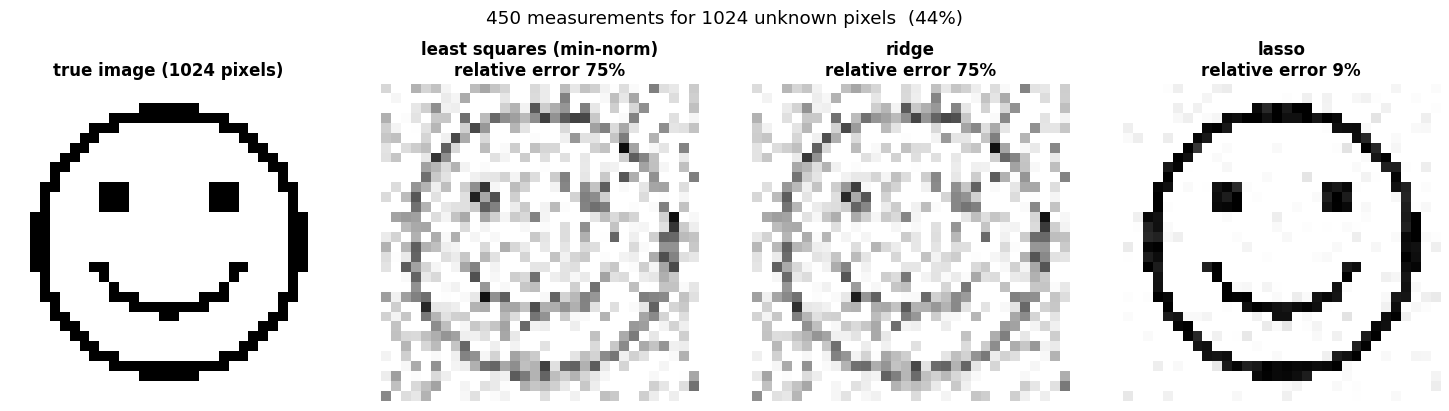

In [13]:
def make_image(s=32):
    yy, xx_ = np.mgrid[0:s, 0:s] / (s - 1) * 2 - 1
    r = np.sqrt(xx_ ** 2 + yy ** 2)
    img = (np.abs(r - 0.85) < 0.045).astype(float)                       # head outline
    img += ((xx_ + 0.35) ** 2 + (yy + 0.3) ** 2 < 0.012)                  # eyes
    img += ((xx_ - 0.35) ** 2 + (yy + 0.3) ** 2 < 0.012)
    img += (np.abs(np.sqrt(xx_ ** 2 + (yy + 0.05) ** 2) - 0.5) < 0.04) * (yy > 0.15)   # smile
    return np.clip(img, 0, 1)

img = make_image(); x_true = img.ravel(); p_img = x_true.size
print(f"{p_img} pixels, only {int(x_true.sum())} of them on ({x_true.mean():.0%}); the other {1-x_true.mean():.0%} are zero")

def reconstruct(n_meas, noise=0.5, seed=0):
    r_ = np.random.default_rng(seed)
    A = r_.normal(size=(n_meas, p_img)) / np.sqrt(n_meas)
    y_meas = A @ x_true + noise * r_.normal(size=n_meas) / np.sqrt(n_meas)
    x_lasso = Lasso(alpha=3e-5, fit_intercept=False, max_iter=20000, positive=True).fit(A, y_meas).coef_   # pixels can't be negative
    x_ridge = Ridge(alpha=0.05, fit_intercept=False).fit(A, y_meas).coef_
    x_ls = np.linalg.pinv(A) @ y_meas                                     # minimum-norm least squares
    return x_ls, x_ridge, x_lasso

def plot_cs(n_meas=450):
    recs = reconstruct(n_meas)
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    axes[0].imshow(img, cmap="gray_r", vmin=0, vmax=1); axes[0].set_title(f"true image ({p_img} pixels)")
    for ax, rec, name in zip(axes[1:], recs, ["least squares (min-norm)", "ridge", "lasso"]):
        err = np.linalg.norm(rec - x_true) / np.linalg.norm(x_true)
        ax.imshow(rec.reshape(img.shape), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"{name}\nrelative error {err:.0%}")
    for ax in axes: ax.axis("off")
    fig.suptitle(f"{n_meas} measurements for {p_img} unknown pixels  ({n_meas / p_img:.0%})", y=1.02)
    fig.tight_layout(); plt.show()

plot_cs(450)

With fewer than half as many measurements as pixels, the Lasso reconstruction is nearly perfect, while least squares and ridge produce gray noise: they spread energy across all pixels (ISYE: ridge "stabilizes solution & spreads energy"), which is exactly wrong for an image that is mostly zeros. (We also told the Lasso that pixel values can't be negative, `positive=True`, a free piece of prior knowledge that sharpens the result.)

🎚️ **How few measurements can you get away with?** Watch for the sudden transition between roughly 350 and 400 measurements: below it the Lasso fails too, and above it recovery is essentially perfect. Ridge only improves gradually.

In [14]:
interact(plot_cs, n_meas=IntSlider(value=450, min=150, max=900, step=25, description="# measurements"));

That sharp threshold is a real, well-studied phenomenon (a "phase transition"): roughly, you need on the order of $k\log(p/k)$ measurements for a $k$-sparse signal, far fewer than $p$. And real images aren't sparse in pixels, but they *are* sparse in other bases (wavelets, gradients), which is why the same math works for actual MRI scans.

---
## 11. Summary

- **Feature selection** = an evaluation metric (CV error, not training error) + a search strategy.
- **Best subset** is exact but costs $2^p$ fits; **forward stepwise** is greedy and cheaper, but unstable.
- **Ridge** ($\ell_2$, Gaussian prior) shrinks smoothly and never selects.
- **Lasso** ($\ell_1$, Laplace prior) is the convex relaxation of best subset. In 1-D it's **soft thresholding**: $S_\lambda(z) = \text{sign}(z)\max(|z|-\lambda, 0)$. The kink at zero is why coefficients become exactly zero; geometrically, it's the corners of the $\ell_1$ ball.
- **Coordinate descent** solves the Lasso by soft-thresholding one coordinate at a time; warm starts give the whole path cheaply.
- **Choose $\lambda$ by CV**; the one-standard-error rule gives sparser models at almost no cost.
- **Elastic net** combines the two penalties: sparse like the Lasso, group-friendly like ridge.
- **Compressed sensing**: sparsity lets the Lasso solve underdetermined systems, which is why MRI scans can be faster.

### ✏️ Exercises

1. Show that for the Lasso, all coefficients are zero exactly when $\lambda \ge \max_j |\frac1m X_j^\top y|$. *(Hint: check when $\theta = 0$ satisfies the "subgradient = 0" condition.)*
2. Implement **backward elimination** on the diabetes data and compare its path with forward stepwise and best subset.
3. Implement **ISTA** (proximal gradient): $\theta \leftarrow S_{\eta\lambda}\big(\theta + \frac{\eta}{m}X^\top(y - X\theta)\big)$ with $\eta = 1/L$, $L$ the largest eigenvalue of $\frac1m X^\top X$. Check it matches `lasso_cd`. Count iterations for both.
4. Implement the **relaxed Lasso** on the synthetic problem of section 8. Does refitting least squares on the selected features reduce $\|\hat\theta - \beta\|$?
5. Run **stability selection**: fit the Lasso (fixed $\lambda$) on 200 random half-samples of the diabetes data, and plot how often each feature is selected.
6. In the compressed-sensing demo, make the image less sparse (add more "on" pixels). How does the measurement threshold move?

### References

- ISYE 4600 W5 (Feature Selection): subset selection, ridge vs. LASSO, 1-D soft thresholding, elastic net, compressive sensing, diabetes and prostate demos; HW2 (medical imaging reconstruction).
- CX 4240 Lecture 6: MAP with a Laplacian prior.
- R. Tibshirani, *Regression Shrinkage and Selection via the Lasso*, JRSS-B (1996).
- J. Friedman, T. Hastie & R. Tibshirani, *Regularization Paths for Generalized Linear Models via Coordinate Descent*, J. Statistical Software (2010) (glmnet).
- H. Zou & T. Hastie, *Regularization and Variable Selection via the Elastic Net*, JRSS-B (2005).
- T. Hastie, R. Tibshirani & M. Wainwright, *Statistical Learning with Sparsity* (2015), Chapters 2–4 and 10.
- E. Candès & M. Wakin, *An Introduction to Compressive Sampling*, IEEE Signal Processing Magazine (2008).

**Next → [08 · Logistic Regression](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/08_logistic_regression.ipynb)**